# TP Web Mining — Análisis 2 · Notebook 1b: dataset sin futuros y baselines

**Objetivo de este análisis:** predecir el precio disponible Matba (Rosario) de soja, maíz y trigo a 30, 60 y 90 días usando **solo** el propio disponible, los precios de Chicago y la lluvia del Corn Belt.

**Los precios futuros no se usan en ningún paso.** Del archivo de Matba se leen únicamente las filas de disponible.

**Este notebook hace:**
1. Carga y limpieza de las tres fuentes (disponible, Chicago, lluvia).
2. Normalización del disponible (`soj.ros/dis23`, `dis24`… → `soj.ros/dis`) tomando el precio de ajuste.
3. Panel de modelado: target (log-retorno a h días) + variables, todas conocidas en la fecha de origen.
4. Partición temporal: tuning 2023-2024, test walk-forward 2025 en adelante, con purga.
5. Baselines: **random walk** y **tendencia promedio**.

El panel queda guardado en `panel_sin_futuros.csv` y las variables diarias en `variables_diarias.csv`, los dos para el Notebook 2b.

## 0. Configuración y carga de archivos

En Colab, la celda siguiente pide subir los 3 CSV si no los encuentra. Si preferís Google Drive, descomentá las dos líneas de `drive.mount` y ajustá `DATA_DIR`.

In [1]:
import os, sys, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

IN_COLAB = "google.colab" in sys.modules
DATA_DIR = os.environ.get("DATA_DIR", "/content" if IN_COLAB else "../data/raw")        # CSV de entrada
OUT_DIR  = os.environ.get("OUT_DIR",  "/content" if IN_COLAB else "../data/processed")  # CSV de salida
os.makedirs(OUT_DIR, exist_ok=True)

# --- Opción Google Drive (descomentar si los CSV están en Drive) ---
# from google.colab import drive; drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/tp_web_mining"

PATRONES = {
    "matba":   "*futuros_y_disponible*.csv",   # de este archivo se usan SOLO las filas de disponible
    "chicago": "*bcr_chicago*.csv",
    "lluvia":  "*prcp_diaria_cornbelt*.csv",
}

def buscar(patron):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, patron)))
    return hits[0] if hits else None

faltan = [k for k, p in PATRONES.items() if buscar(p) is None]
if faltan and IN_COLAB:
    from google.colab import files
    print("Subí estos archivos:", faltan)
    files.upload()
    faltan = [k for k, p in PATRONES.items() if buscar(p) is None]
assert not faltan, f"No encuentro los archivos: {faltan} en {DATA_DIR}"

RUTAS = {k: buscar(p) for k, p in PATRONES.items()}
RUTAS

{'matba': '../data/raw/futuros_y_disponible_agropecuario_2023_a_hoy.csv',
 'chicago': '../data/raw/bcr_chicago_1.csv',
 'lluvia': '../data/raw/prcp_diaria_cornbelt.csv'}

In [2]:
HORIZONTES   = [30, 60, 90]                    # días calendario
ESPECIES     = {"SOJ": "soja", "MAI": "maiz", "TRI": "trigo"}
FIN_TUNING   = pd.Timestamp("2024-12-31")      # 2023-2024: elegir variables e hiperparámetros
INICIO_TEST  = pd.Timestamp("2025-01-01")      # 2025 en adelante: evaluación walk-forward
MESES_CRITICOS_CORNBELT = [6, 7, 8]            # polinización maíz / llenado soja

## 1. Disponible: normalización de posiciones

Del archivo de Matba se toman **solo las filas con `tipo_instrumento == "disponible"`**; los futuros se descartan acá y no vuelven a aparecer.

Cada año tiene su símbolo (`SOJ.ROS/DIS25`, `SOJ.ROS/DIS26`…). En los primeros días hábiles de enero cotizan los dos con el mismo ajuste, así que nos quedamos con **el contrato cuyo año coincide con el año de la fecha**. El resultado es una serie continua por especie (`soj.ros/dis`, `mai.ros/dis`, `tri.ros/dis`) con el precio de ajuste (`settlement`, USD/t).

In [3]:
raw = pd.read_csv(RUTAS["matba"], sep=";")
print("Filas por tipo en el archivo original:", raw.tipo_instrumento.value_counts().to_dict())

disp = raw[(raw.tipo_instrumento == "disponible")
           & raw.symbol.str.match(r"^(SOJ|MAI|TRI)\.ROS/DIS\d{2}$")].copy()
del raw   # a partir de acá no queda ningún precio futuro en memoria

disp["fecha"] = pd.to_datetime(disp["dateTime"], utc=True).dt.tz_convert(None).dt.normalize()
disp["especie"]       = disp.symbol.str[:3].map(ESPECIES)
disp["anio_contrato"] = 2000 + disp.symbol.str[-2:].astype(int)
disp["symbol_norm"]   = disp.symbol.str.replace(r"\d{2}$", "", regex=True).str.lower()

n0 = len(disp)
disp = disp[disp.anio_contrato == disp.fecha.dt.year]
print(f"Filas descartadas por solapamiento de contratos: {n0 - len(disp)}")
assert not disp.duplicated(["especie", "fecha"]).any()

spot = disp.pivot(index="fecha", columns="especie", values="settlement").sort_index()[["soja", "maiz", "trigo"]]
print(disp.groupby("symbol_norm").symbol.unique())
print(spot.index.min().date(), "→", spot.index.max().date(), "| ruedas:", len(spot))
print("\nNaN por especie:\n", spot.isna().sum())
spot.describe().round(1)

Filas por tipo en el archivo original: {'futuro': 30327, 'disponible': 3666}
Filas descartadas por solapamiento de contratos: 19
symbol_norm
mai.ros/dis    [MAI.ROS/DIS23, MAI.ROS/DIS24, MAI.ROS/DIS25, ...
soj.ros/dis    [SOJ.ROS/DIS23, SOJ.ROS/DIS24, SOJ.ROS/DIS25, ...
tri.ros/dis    [TRI.ROS/DIS23, TRI.ROS/DIS24, TRI.ROS/DIS25, ...
Name: symbol, dtype: object
2023-01-02 → 2026-09-24 | ruedas: 908

NaN por especie:
 especie
soja     0
maiz     0
trigo    0
dtype: int64


especie,soja,maiz,trigo
count,908.0,908.0,908.0
mean,344.1,195.9,231.3
std,65.7,26.2,41.7
min,254.5,166.0,169.0
25%,303.4,180.0,200.0
50%,326.0,186.8,218.0
75%,355.6,199.6,263.0
max,620.0,280.0,331.0


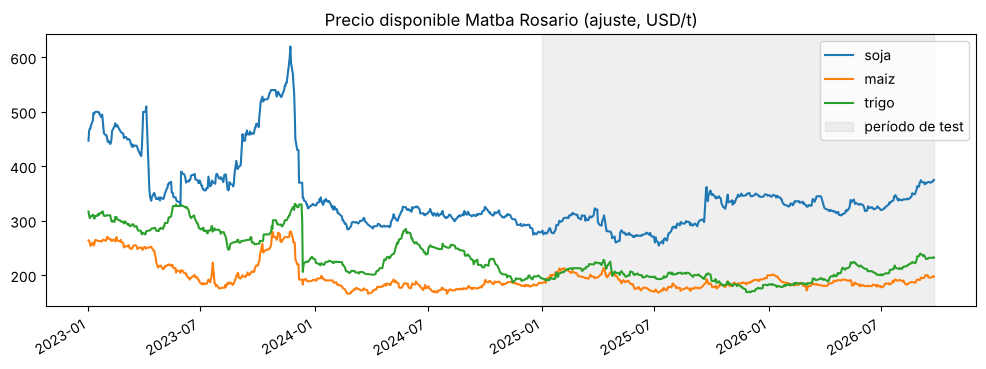

Días con variación diaria > 6% (candidatos a cambio de régimen):


,fecha,especie,ret
180,2023-03-30,soja,6.2
183,2023-03-31,soja,7.3
195,2023-04-10,soja,-35.8
297,2023-05-31,soja,17.6
403,2023-07-21,maiz,7.0
406,2023-07-24,maiz,-18.7
450,2023-08-14,soja,-7.6
452,2023-08-14,trigo,-7.7
477,2023-08-28,soja,6.0
568,2023-10-09,maiz,6.4


In [4]:
ax = spot.plot(figsize=(12, 4), title="Precio disponible Matba Rosario (ajuste, USD/t)")
ax.axvspan(INICIO_TEST, spot.index.max(), color="grey", alpha=.12, label="período de test")
ax.set_xlabel(""); ax.legend(); plt.show()

# Saltos diarios grandes: ayudan a identificar cambios de régimen
# (programas de dólar diferencial, cambios de retenciones). Verificar fechas y armar dummies.
saltos = np.log(spot).diff().stack().rename("ret").reset_index()
saltos = saltos[saltos.ret.abs() > 0.06].sort_values("fecha")
print("Días con variación diaria > 6% (candidatos a cambio de régimen):")
saltos.assign(ret=lambda d: (d.ret * 100).round(1))

**Dummies de régimen (a completar).** Con la tabla de saltos de arriba, identificar los períodos con dólar diferencial o cambios de retenciones y cargarlos acá. Quedan como variables `reg_*` en el panel. Si se deja vacío, el panel se arma igual sin ellas.

In [5]:
# Formato: "nombre": ("fecha_desde", "fecha_hasta")   — VERIFICAR fechas con fuentes oficiales
REGIMENES = {
    # "dolar_diferencial_1": ("2023-04-08", "2023-05-31"),
}

## 2. Chicago (BCR)

- Coma decimal y fechas `dd/mm/aaaa`.
- El archivo trae **precio 0** en algunas fechas: son datos faltantes, no precios reales, y se tratan como NaN.
- La columna *posición* cambia cuando BCR pasa al contrato siguiente: ese día la variación de precio es un **salto de roll**, no un movimiento de mercado. Se arma un índice continuo poniendo en cero el retorno de esos días.
- Para evitar leakage, en cada fecha de Rosario se usa **el último dato de Chicago estrictamente anterior** (t-1). Esto también resuelve los feriados distintos de cada país.

Fechas con precio 0 (se tratan como faltantes): ['17/03/2025', '15/07/2026', '16/07/2026', '17/07/2026']
2023-01-03 → 2026-10-01 | filas: 809
Días de roll por especie:
 trigo    19
maiz     21
soja     27
dtype: int64


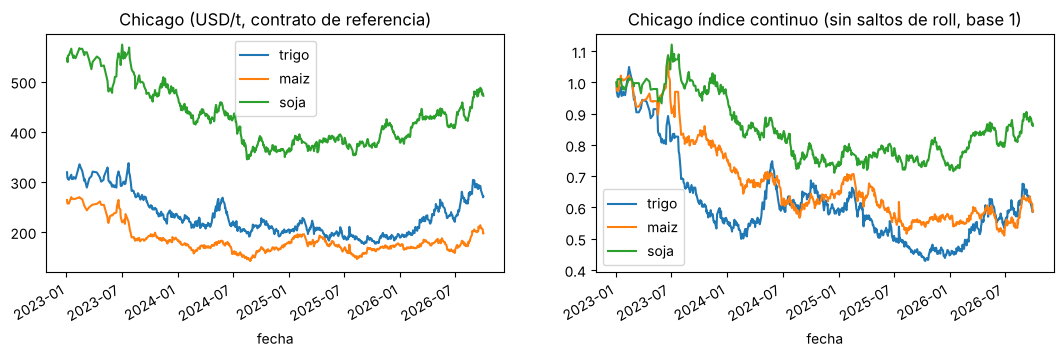

In [6]:
chi_raw = pd.read_csv(RUTAS["chicago"], sep=";", encoding="utf-8-sig", decimal=",")
chi_raw.columns = [c.strip() for c in chi_raw.columns]
chi_raw["fecha"] = pd.to_datetime(chi_raw["Fecha"], dayfirst=True)

def col_chi(prefijo, sufijo=""):
    for c in chi_raw.columns:
        base = c.lower()
        if base.startswith(prefijo) and (base.endswith(sufijo) if sufijo else re.search(r"/\d$", base)):
            return c
    raise KeyError(prefijo + sufijo)

mapa = {"trigo": "trigo chicago", "maiz": "ma", "soja": "soja chicago"}
chi_px, chi_pos = {}, {}
for esp, pref in mapa.items():
    chi_px[esp]  = chi_raw.set_index("fecha")[col_chi(pref)]
    chi_pos[esp] = chi_raw.set_index("fecha")[col_chi(pref, "posición")]
chi_px  = pd.DataFrame(chi_px).astype(float)
chi_pos = pd.DataFrame(chi_pos)

ceros = chi_px.index[(chi_px <= 0).any(axis=1)]
print("Fechas con precio 0 (se tratan como faltantes):", [d.strftime("%d/%m/%Y") for d in ceros])
chi_px = chi_px.where(chi_px > 0)

chi_px = chi_px.dropna(how="all").sort_index()
chi_pos = chi_pos.loc[chi_px.index]
print(chi_px.index.min().date(), "→", chi_px.index.max().date(), "| filas:", len(chi_px))

ret_chi = np.log(chi_px).diff()
roll = chi_pos.ne(chi_pos.shift()) & chi_pos.shift().notna()
print("Días de roll por especie:\n", roll.sum())
ret_chi = ret_chi.mask(roll, 0.0).fillna(0.0)
chi_idx = ret_chi.cumsum()          # log-precio ajustado (nivel arbitrario)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
chi_px.plot(ax=ax[0], title="Chicago (USD/t, contrato de referencia)")
np.exp(chi_idx).plot(ax=ax[1], title="Chicago índice continuo (sin saltos de roll, base 1)")
plt.show()

## 3. Lluvia Corn Belt

- Lluvia diaria promedio de los 8 estados. **Pesos iguales por defecto**: conviene reemplazarlos por la participación de cada estado en la producción de maíz/soja (USDA NASS).
- Acumulados de 30 y 60 días expresados como **anomalía**: acumulado − promedio histórico de ese mes. La climatología se calcula **solo con datos hasta el fin del período de tuning**, para no usar información futura.
- Se usa el dato del día anterior (t-1). Los valores `preliminar` del final se usan tal cual.

{'final': 14608, 'preliminar': 224} | 2021-09-01 → 2026-09-28


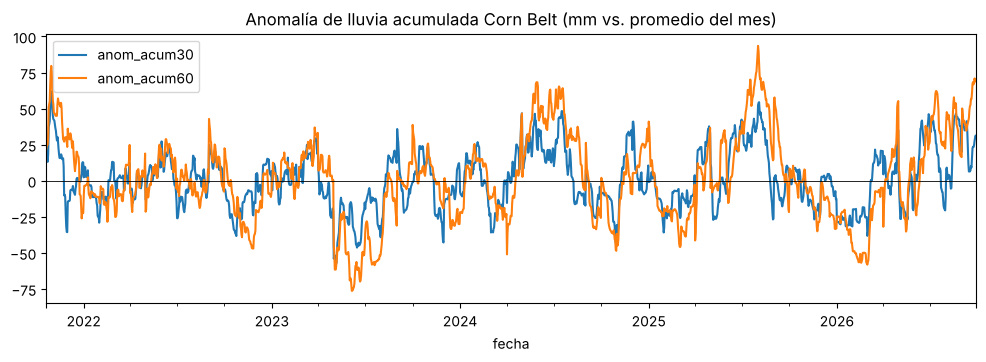

In [7]:
pr = pd.read_csv(RUTAS["lluvia"], parse_dates=["fecha"])
print(pr.calidad.value_counts().to_dict(), "|", pr.fecha.min().date(), "→", pr.fecha.max().date())
pr_w = pr.pivot_table(index="fecha", columns="estado", values="precip_mm").asfreq("D")

PESOS = {e: 1 / pr_w.shape[1] for e in pr_w.columns}   # TODO: pesos por producción (USDA NASS)
w = pd.Series(PESOS)
lluvia = (pr_w * w).sum(axis=1, min_count=1) / pr_w.notna().mul(w).sum(axis=1)

clima = pd.DataFrame({"acum30": lluvia.rolling(30, min_periods=25).sum(),
                      "acum60": lluvia.rolling(60, min_periods=50).sum()})
base_clim = clima[clima.index <= FIN_TUNING]
clim_mes = base_clim.groupby(base_clim.index.month).mean()
for c in ["acum30", "acum60"]:
    clima[f"anom_{c}"] = clima[c] - clima.index.month.map(clim_mes[c]).values
clima = clima.dropna()

ax = clima[["anom_acum30", "anom_acum60"]].plot(figsize=(12, 3.5),
        title="Anomalía de lluvia acumulada Corn Belt (mm vs. promedio del mes)")
ax.axhline(0, color="k", lw=.6); plt.show()

## 4. Panel de modelado

Una fila por **(fecha de origen t, especie, horizonte h)**.

- **Fecha objetivo:** primera rueda con disponible ≥ t + h días.
- **Target:** `y = log(P_objetivo / P_t)`. La predicción de precio se reconstruye como `P_t · exp(ŷ)`.
- **Variables**, todas conocidas al cierre de t y agrupadas por fuente para poder medir cuánto aporta cada una en el Notebook 2b:

| Fuente | Variables |
|---|---|
| Propio disponible | `ret_5`, `ret_21`, `ret_63`, `vol_21`, `dist_ma63` |
| Calendario | `mes_sin`, `mes_cos` |
| Chicago (t-1) | `chi_ret_5`, `chi_ret_21`, `chi_ret_63`, `base`, `base_desvio` |
| Clima (t-1) | `anom_acum30`, `anom_acum60`, `critico`, `clima_x_critico` (solo soja/maíz) |
| Régimen | `reg_*` (si se cargan) |

In [8]:
def asof_anterior(idx_destino, df_origen):
    # Para cada fecha destino, la última fila de df_origen con fecha ESTRICTAMENTE anterior (t-1)
    izq = pd.DataFrame({"fecha": idx_destino})
    der = df_origen.reset_index().rename(columns={df_origen.index.name or "index": "fecha"}).sort_values("fecha")
    m = pd.merge_asof(izq, der, on="fecha", direction="backward", allow_exact_matches=False)
    return m.set_index("fecha")

bloques = []
for esp in ESPECIES.values():
    p = spot[esp].dropna()
    lp = np.log(p)
    r1 = lp.diff()
    f = pd.DataFrame(index=p.index)
    f["especie"] = esp
    f["P_t"] = p
    for k in [5, 21, 63]:
        f[f"ret_{k}"] = lp - lp.shift(k)
    f["vol_21"] = r1.rolling(21).std()
    f["dist_ma63"] = lp - np.log(p.rolling(63).mean())

    ch = asof_anterior(p.index, pd.DataFrame({"chi_idx": chi_idx[esp], "chi_px": chi_px[esp].ffill()}))
    for k in [5, 21, 63]:
        f[f"chi_ret_{k}"] = (ch.chi_idx - ch.chi_idx.shift(k)).values
    f["base"] = (lp - np.log(ch.chi_px)).values
    f["base_desvio"] = f["base"] - f["base"].rolling(126, min_periods=63).mean()

    cl = asof_anterior(p.index, clima[["anom_acum30", "anom_acum60"]])
    f["anom_acum30"] = cl.anom_acum30.values
    f["anom_acum60"] = cl.anom_acum60.values
    f["critico"] = f.index.month.isin(MESES_CRITICOS_CORNBELT).astype(int)
    f["clima_x_critico"] = f["anom_acum30"] * f["critico"] * (esp != "trigo")

    f["mes_sin"] = np.sin(2 * np.pi * f.index.month / 12)
    f["mes_cos"] = np.cos(2 * np.pi * f.index.month / 12)
    for nombre, (d0, d1) in REGIMENES.items():
        f[f"reg_{nombre}"] = ((f.index >= d0) & (f.index <= d1)).astype(int)

    fechas = p.index.values
    for h in HORIZONTES:
        g = f.copy()
        g["h"] = h
        objetivo = p.index + pd.Timedelta(days=h)
        pos = np.searchsorted(fechas, objetivo.values)
        ok = pos < len(fechas)
        g["fecha_obj"] = pd.NaT
        g.loc[ok, "fecha_obj"] = fechas[pos[ok]]
        g["P_obj"] = np.nan
        g.loc[ok, "P_obj"] = p.values[pos[ok]]
        g["y"] = np.log(g.P_obj / g.P_t)
        bloques.append(g)

panel = pd.concat(bloques).rename_axis("fecha").reset_index()
panel["fecha_obj"] = pd.to_datetime(panel["fecha_obj"])

# Variables de TODOS los días, incluidos los últimos que todavía no tienen target:
# sirven para el pronóstico real hacia adelante en el Notebook 2b
diarias = (panel[panel.h == HORIZONTES[0]].drop(columns=["h", "fecha_obj", "P_obj", "y"])
           .sort_values(["especie", "fecha"]))
print("Última fecha por especie:", diarias.groupby("especie").fecha.max().dt.date.to_dict())

panel = panel[(panel.fecha_obj - panel.fecha).dt.days <= panel.h + 7]   # target válido y cercano a t+h
print(panel.shape)
panel.groupby(["especie", "h"]).agg(filas=("y", "size"), desde=("fecha", "min"), hasta=("fecha", "max"),
                                     y_media=("y", "mean"), y_desvio=("y", "std")).round(4)

Última fecha por especie: {'maiz': datetime.date(2026, 9, 24), 'soja': datetime.date(2026, 9, 24), 'trigo': datetime.date(2026, 9, 24)}
(7794, 23)


filas      desde      hasta  y_media  y_desvio
especie h                                                 
maiz    30    886 2023-01-02 2026-08-25  -0.0072    0.0829
        60    865 2023-01-02 2026-07-24  -0.0144    0.1206
        90    847 2023-01-02 2026-06-26  -0.0212    0.1435
soja    30    886 2023-01-02 2026-08-25  -0.0058    0.1079
        60    865 2023-01-02 2026-07-24  -0.0131    0.1536
        90    847 2023-01-02 2026-06-26  -0.0205    0.1896
trigo   30    886 2023-01-02 2026-08-25  -0.0072    0.0880
        60    865 2023-01-02 2026-07-24  -0.0159    0.1195
        90    847 2023-01-02 2026-06-26  -0.0234    0.1391

## 5. Partición temporal y purga

- **`tuning`**: origen y fecha objetivo dentro de 2023-2024. Se usa para elegir variables e hiperparámetros.
- **`purga`**: el origen está en 2024 pero el target cae en 2025. Se descartan para que el tuning no "vea" precios del período de test.
- **`test`**: origen desde 2025-01-01. Se evalúa con **walk-forward mensual**: para predecir el mes M se entrena solo con filas cuyo target ya se conocía antes del primer día de M.

In [9]:
panel["conjunto"] = np.select(
    [panel.fecha_obj <= FIN_TUNING, panel.fecha <= FIN_TUNING, panel.fecha >= INICIO_TEST],
    ["tuning", "purga", "test"], default="otro")
print(panel.groupby(["h", "conjunto"]).size().unstack())

def folds_walk_forward(df, h):
    # (mes, idx_train, idx_test): para cada mes de test, train = filas con target conocido antes del mes
    d = df[df.h == h]
    for m in pd.period_range(INICIO_TEST, d.fecha.max(), freq="M"):
        ini = m.start_time
        idx_test = d.index[(d.fecha >= ini) & (d.fecha <= m.end_time)]
        idx_train = d.index[d.fecha_obj < ini]
        if len(idx_test):
            yield m, idx_train, idx_test

conjunto  purga  test  tuning
h                            
30           57  1191    1410
60          117  1128    1350
90          180  1074    1287


## 6. Baselines y métricas

Sin futuros, la vara contra la que se miden los modelos son dos reglas simples:

- **Random walk:** ŷ = 0, o sea "el precio dentro de h días va a ser el de hoy".
- **Tendencia promedio:** ŷ = cambio promedio a h días observado hasta el mes anterior (walk-forward). Captura si el precio venía bajando o subiendo en promedio.

| Métrica | Escala | Lectura |
|---|---|---|
| MAE, RMSE (USD/t), MAPE (%) | precio | Error en lo que importa al productor |
| `R2_niveles` | precio | **Engañoso**: se muestra solo para ver la "trampa" |
| `R2_ret` | retorno | R² clásico sobre el cambio predicho |
| `R2_oos_vs_RW` | retorno | 1 − SSE_modelo / SSE_random walk. **> 0 significa que le gana al random walk** |
| `acierto_dir_%` | retorno | % de veces que acierta si sube o baja |
| `DM_p_vs_RW` | — | p-valor de Diebold-Mariano contra el random walk |

In [10]:
def diebold_mariano(e_modelo, e_bench, h_ruedas):
    # H0: igual error cuadrático. Estadístico < 0 => el modelo tiene menor error. Devuelve (estadístico, p-valor)
    d = np.asarray(e_modelo) ** 2 - np.asarray(e_bench) ** 2
    T = len(d)
    if T < 10 or np.allclose(d, 0):
        return np.nan, np.nan
    dc = d - d.mean()
    lag = max(int(h_ruedas) - 1, 0)
    gamma = [dc @ dc / T] + [dc[k:] @ dc[:-k] / T for k in range(1, lag + 1)]
    var = gamma[0] + 2 * sum((1 - k / (lag + 1)) * gamma[k] for k in range(1, lag + 1))
    if var <= 0:
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(var / T)
    dm *= np.sqrt((T + 1 - 2 * (lag + 1) + (lag + 1) * lag / T) / T)   # corrección HLN
    return dm, 2 * stats.t.sf(abs(dm), df=T - 1)

def metricas(d, col):
    y, yhat = d.y.values, d[col].values
    P_hat = d.P_t.values * np.exp(yhat)
    err = d.P_obj.values - P_hat
    sse = np.sum((y - yhat) ** 2)
    out = {
        "n": len(d),
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAPE_%": 100 * np.mean(np.abs(err) / d.P_obj.values),
        "R2_niveles": 1 - np.sum(err ** 2) / np.sum((d.P_obj - d.P_obj.mean()) ** 2),
        "R2_ret": 1 - sse / np.sum((y - y.mean()) ** 2),
        "R2_oos_vs_RW": 1 - sse / np.sum(y ** 2),
        "acierto_dir_%": 100 * np.mean(np.sign(yhat[yhat != 0]) == np.sign(y[yhat != 0])) if np.any(yhat != 0) else np.nan,
    }
    h_ruedas = round(d.h.iloc[0] * 252 / 365)
    out["DM_stat_vs_RW"], out["DM_p_vs_RW"] = diebold_mariano(y - yhat, y, h_ruedas)
    return out

panel["pred_rw"] = 0.0
panel["pred_tendencia"] = np.nan
for h in HORIZONTES:
    for m, idx_tr, idx_te in folds_walk_forward(panel, h):
        tr = panel.loc[idx_tr]
        # cambio promedio por especie, con lo conocido antes del mes
        medias = tr.groupby("especie").y.mean()
        panel.loc[idx_te, "pred_tendencia"] = panel.loc[idx_te, "especie"].map(medias).values

test = panel[panel.conjunto == "test"].dropna(subset=["y", "pred_tendencia"])
filas = []
for (esp, h), g in test.groupby(["especie", "h"]):
    for modelo in ["rw", "tendencia"]:
        filas.append({"especie": esp, "h": h, "modelo": modelo, **metricas(g, f"pred_{modelo}")})
res_base = pd.DataFrame(filas).set_index(["especie", "h", "modelo"])
res_base.round(3)

n     MAE    RMSE  MAPE_%  R2_niveles  R2_ret  R2_oos_vs_RW  acierto_dir_%  DM_stat_vs_RW  DM_p_vs_RW
especie h  modelo                                                                                                            
maiz    30 rw         397   7.508   9.254   3.995       0.026  -0.000         0.000            NaN            NaN         NaN
           tendencia  397   7.837   9.446   4.153      -0.015  -0.059        -0.059         44.836          0.675       0.500
        60 rw         376   8.853  11.285   4.816      -0.840  -0.009         0.000            NaN            NaN         NaN
           tendencia  376   9.528  11.537   5.154      -0.923  -0.090        -0.080         45.479          0.410       0.682
        90 rw         358  10.394  13.225   5.650      -1.622  -0.014         0.000            NaN            NaN         NaN
           tendencia  358  11.452  13.660   6.151      -1.797  -0.134        -0.118         50.559          0.340       0.734
soja    30 rw         397  14.848  19.966   4.658       0.505  -0.063         0.000            NaN            NaN         NaN
           tendencia  397  16.209  21.595   5.057       0.421  -0.265        -0.189         41.814          1.870       0.062
        60 rw         376  20.894  26.518   6.579       0.171  -0.065         0.000            NaN            NaN         NaN
           tendencia  376  23.332  30.179   7.233      -0.074  -0.416        -0.330         40.957          1.304       0.193
        90 rw         358  26.648  33.631   8.313      -0.260  -0.061         0.000            NaN            NaN         NaN
           tendencia  358  29.477  39.094   8.993      -0.703  -0.489        -0.403         45.531          1.051       0.294
trigo   30 rw         397   9.370  11.265   4.613       0.486  -0.027         0.000            NaN            NaN         NaN
           tendencia  397  10.125  12.145   4.945       0.402  -0.208        -0.176         41.814          1.639       0.102
        60 rw         376  12.869  15.608   6.366      -0.006  -0.018         0.000            NaN            NaN         NaN
           tendencia  376  14.234  17.335   6.964      -0.241  -0.289        -0.266         44.947          1.160       0.247
        90 rw         358  14.688  18.109   7.360      -0.301  -0.009         0.000            NaN            NaN         NaN
           tendencia  358  16.666  20.446   8.187      -0.658  -0.331        -0.319         45.531          0.868       0.386

**Cómo leer la tabla**

- El random walk tiene `R2_oos_vs_RW = 0` por definición. Su `R2_niveles` puede salir alto o bajo según cuánto se movió el precio en el período: por eso el R² en niveles no sirve para decidir si un modelo sabe algo.
- Si la tendencia promedio da `R2_oos_vs_RW < 0`, el precio no siguió en 2025-26 la dirección que traía: extrapolar el pasado empeora la predicción.

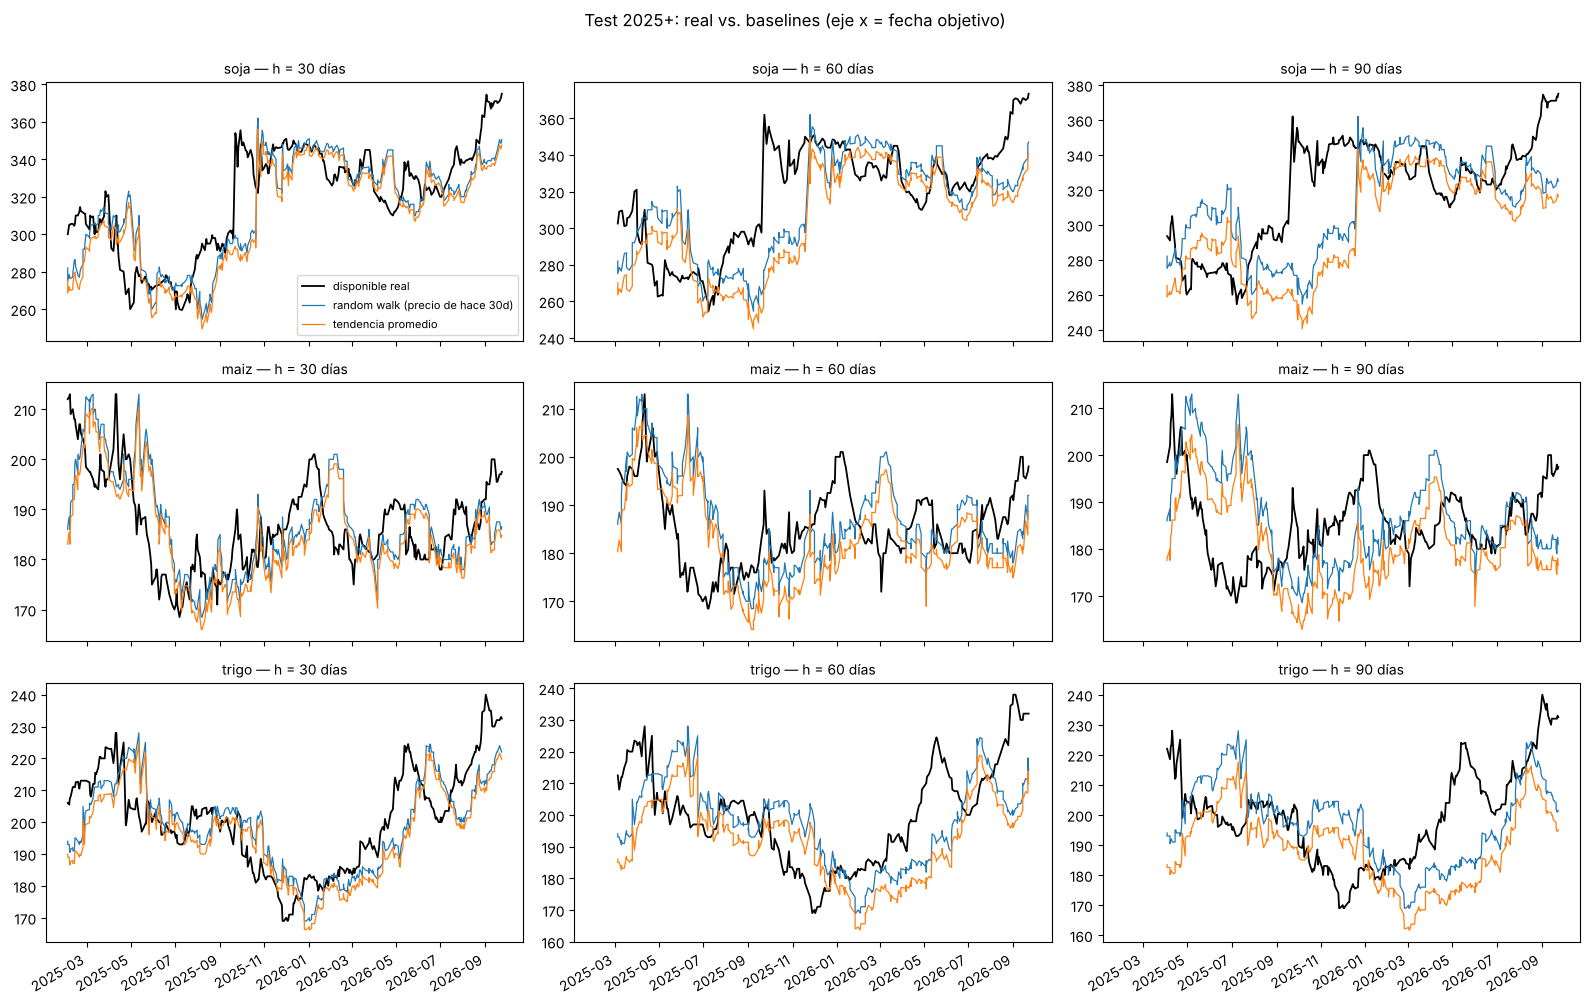

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharex=True)
for i, esp in enumerate(ESPECIES.values()):
    for j, h in enumerate(HORIZONTES):
        g = test[(test.especie == esp) & (test.h == h)].set_index("fecha_obj").sort_index()
        ax = axes[i, j]
        ax.plot(g.index, g.P_obj, color="k", lw=1.3, label="disponible real")
        ax.plot(g.index, g.P_t, lw=.9, label=f"random walk (precio de hace {h}d)")
        ax.plot(g.index, g.P_t * np.exp(g.pred_tendencia), lw=.9, label="tendencia promedio")
        ax.set_title(f"{esp} — h = {h} días", fontsize=10)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Test 2025+: real vs. baselines (eje x = fecha objetivo)", y=1.0)
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## 7. Guardar el panel

- `panel_sin_futuros.csv`: variables, target, conjunto y predicciones de los baselines. No contiene ninguna columna derivada de precios futuros.
- `variables_diarias.csv`: las variables de todos los días, incluido el último con dato, para el pronóstico hacia adelante del Notebook 2b.

In [12]:
VARS_PRECIO     = ["ret_5", "ret_21", "ret_63", "vol_21", "dist_ma63", "mes_sin", "mes_cos"] + \
                  [c for c in panel.columns if c.startswith("reg_")]
VARS_CHICAGO    = ["chi_ret_5", "chi_ret_21", "chi_ret_63", "base", "base_desvio"]
VARS_CLIMA      = ["anom_acum30", "anom_acum60", "critico", "clima_x_critico"]
VARS_COMPLETO   = VARS_PRECIO + VARS_CHICAGO + VARS_CLIMA

assert not any("fut" in c.lower() for c in panel.columns), "Quedó una columna de futuros"
completo = panel.dropna(subset=VARS_COMPLETO + ["y"])
print(f"Filas con todas las variables: {len(completo)} de {len(panel)}")
print("Nulos por variable (panel completo):")
print(panel[VARS_COMPLETO].isna().sum()[lambda s: s > 0])

panel.to_csv(os.path.join(OUT_DIR, "panel_sin_futuros.csv"), index=False)
diarias.to_csv(os.path.join(OUT_DIR, "variables_diarias.csv"), index=False)
res_base.to_csv(os.path.join(OUT_DIR, "resultados_baselines_sin_futuros.csv"))
print("\nGuardado: panel_sin_futuros.csv, variables_diarias.csv, resultados_baselines_sin_futuros.csv")

if IN_COLAB:
    from google.colab import files
    # files.download(os.path.join(OUT_DIR, "panel_sin_futuros.csv")); files.download(os.path.join(OUT_DIR, "variables_diarias.csv"))   # descomentar para bajarlos

Filas con todas las variables: 7209 de 7794
Nulos por variable (panel completo):
ret_5           45
ret_21         189
ret_63         567
vol_21         189
dist_ma63      558
chi_ret_5       63
chi_ret_21     207
chi_ret_63     585
base            18
base_desvio    576
dtype: int64



Guardado: panel_sin_futuros.csv, variables_diarias.csv, resultados_baselines_sin_futuros.csv
